CDF: 939 matrices at 1e-5 (diag init)

Matrix 973: loading C:\Users\nhajl\Desktop\Current_Work\matrices_under_2G\973.mat
  AMD/G2_circuit, n=150,102, nnz=726,674
  greedy:  15 iters, final relerr=8.42e-06
  lanczos: 97 iters, final relerr=9.60e-06
  power:   27768 iters, final relerr=1.00e-05

Matrix 841: loading C:\Users\nhajl\Desktop\Current_Work\matrices_under_2G\841.mat
  GHS_indef/copter2, n=55,476, nnz=759,952
  greedy:  11 iters, final relerr=6.09e-06
  lanczos: 29 iters, final relerr=9.53e-06
  power:   118 iters, final relerr=9.62e-06

Saved greedy_vs_lanczos_panel.png and .pdf


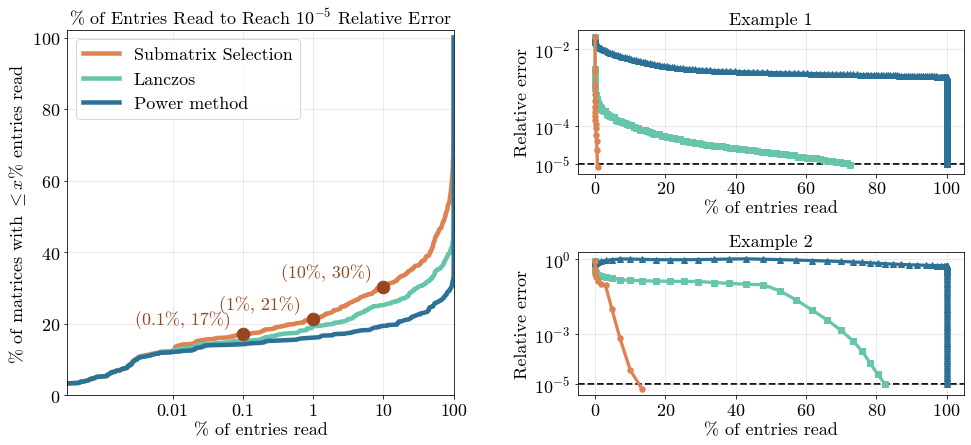

In [4]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import gc

# ══════════════════════════════════════════════════════════════════
#  Matplotlib rcParams 
# ══════════════════════════════════════════════════════════════════
SCALE = 1.8

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "font.size":       round(10 * SCALE),   
    "axes.titlesize":  round(10 * SCALE),   
    "axes.labelsize":  round(10 * SCALE),   
    "xtick.labelsize": round(10 * SCALE),   
    "ytick.labelsize": round(10 * SCALE),   
    "legend.fontsize": round(10 * SCALE),   
})

COLOR_GREEDY  = "#DE8252"
COLOR_ANNOTATION = "#99451F"  # Dark orange for readable CDF callouts
COLOR_LANCZOS = "#66C5AB"   
COLOR_POWER   = "#2D7296"      

# ══════════════════════════════════════════════════════════════════
#  Configuration
# ══════════════════════════════════════════════════════════════════
GREEDY_RESULTS  = r"C:\Users\nhajl\Desktop\Current_Work\greedy_sparse_clean\suitesparse\plotting\CDF_plots\greedy_unsparsified.mat"
LANCZOS_RESULTS = r"C:\Users\nhajl\Desktop\Current_Work\greedy_sparse_clean\suitesparse\plotting\CDF_plots\lanczos_unsparsified.mat"
POWER_RESULTS   = r"C:\Users\nhajl\Desktop\Current_Work\greedy_sparse_clean\suitesparse\plotting\CDF_plots\power_unsparsified.mat"
MATRIX_DIR      = r"C:\Users\nhajl\Desktop\Current_Work\matrices_under_2G"
INIT_COND       = "diag"
TARGET_LEVEL    = 5        # plotting relerr 10^{-TARGET_LEVEL}

# Matrices for the two right-hand convergence plots
MAT_IDS = [973, 841]




# ══════════════════════════════════════════════════════════════════
#  Helpers
# ══════════════════════════════════════════════════════════════════
def nnz_sub(A_csc, mask):
    """Count nnz(A[S,S]) via boolean mask without forming submatrix."""
    count = 0
    for j in np.where(mask)[0]:
        s, e = A_csc.indptr[j], A_csc.indptr[j + 1]
        count += mask[A_csc.indices[s:e]].sum()
    return int(count)


def run_both(A, eigval, ind, seed=42):
    """Run greedy and Lanczos on matrix A, return (relerrs, viewed) for each."""
    n = A.shape[0]
    total_nnz = A.nnz

    # ── Greedy ─────────────────────────────────────────────────
    np.random.seed(seed)
    rg = []; vg = []
    S = [ind]; Sm = np.zeros(n, dtype=bool); Sm[ind] = True
    found = 0

    for it in range(1, 50_001):
        Sa = np.array(S)
        Asub = A[np.ix_(Sa, Sa)]
        nS = len(S)

        if nS == 1:
            ev = Asub[0, 0]
            if sp.issparse(ev):
                ev = ev.toarray().item()
        elif nS < 200:
            vs = np.linalg.eigvalsh(Asub.toarray())
            ev = vs[np.argmax(np.abs(vs))]
        else:
            ev = float(np.real(
                spla.eigs(Asub, k=1, which='LM', return_eigenvectors=False)[0]))

        re = abs(abs(ev) - abs(eigval)) / abs(eigval)
        rg.append(re)
        vg.append(Asub.nnz / total_nnz)
        del Asub

        for k in range(1, 11):
            if re < 10 ** (-k) and found < k:
                found = k
        if found >= TARGET_LEVEL:
            break

        r = A[:, Sa] @ np.random.randn(nS)
        if sp.issparse(r):
            r = r.toarray().ravel()
        nm = np.zeros(n, dtype=bool)
        nm[np.nonzero(r)[0]] = True
        nm |= Sm
        del r
        if nm.sum() == Sm.sum():
            break
        Sm = nm
        S = np.where(Sm)[0].tolist()

    gc.collect()

    # ── Lanczos ────────────────────────────
    rl = []; vl = []
    alphas = np.zeros(n); betas = np.zeros(n)
    vjn = np.zeros(n); vj = np.zeros(n); vj[ind] = 1.0
    Sl = np.zeros(n, dtype=bool); Sl[ind] = True

    wj = A @ vj
    if sp.issparse(wj):
        wj = wj.toarray().ravel()
    alphas[0] = wj @ vj
    wj -= alphas[0] * vj

    re = abs(abs(alphas[0]) - abs(eigval)) / abs(eigval)
    rl.append(re)
    vl.append(nnz_sub(A, Sl) / total_nnz)

    wjn = wj.copy(); vjn = vj.copy()
    found = 0
    for k in range(1, 11):
        if re < 10 ** (-k) and found < k:
            found = k

    for it in range(1, n):
        b = np.linalg.norm(wjn)
        if b == 0:
            break
        betas[it] = b
        vj = wjn / b
        wj = A @ vj
        if sp.issparse(wj):
            wj = wj.toarray().ravel()
        wj -= b * vjn
        alphas[it] = wj @ vj
        wj -= alphas[it] * vj

        Sl[np.nonzero(vj)[0]] = True

        m = it + 1
        T = sp.diags([betas[1:m], alphas[:m], betas[1:m]],
                      [-1, 0, 1], shape=(m, m))
        if m < 200:
            ev_T = np.linalg.eigvalsh(T.toarray())
            ev_l = ev_T[np.argmax(np.abs(ev_T))]
        else:
            ev_l = float(np.real(
                spla.eigs(T.tocsc(), k=1, which='LM',
                          return_eigenvectors=False)[0]))

        re = abs(abs(ev_l) - abs(eigval)) / abs(eigval)
        rl.append(re)
        vl.append(nnz_sub(A, Sl) / total_nnz)

        for k in range(1, 11):
            if re < 10 ** (-k) and found < k:
                found = k
        if found >= TARGET_LEVEL:
            break

        wjn = wj.copy(); vjn = vj.copy()

    del alphas, betas, vjn, vj, wj, wjn
    gc.collect()
    return rg, vg, rl, vl

def run_power(A, eigval, ind, max_iter=50_000):
    n = A.shape[0]
    total_nnz = A.nnz

    A_csc = sp.csc_matrix(A)

    row_idx = A_csc.indices
    col_idx = np.repeat(np.arange(n), np.diff(A_csc.indptr))

    def nnz_in(mask):
        return int(np.count_nonzero(mask[row_idx] & mask[col_idx]))

    P = (A_csc != 0).astype(np.int32).tocsr()

    rp = []; vp = []
    v = np.zeros(n); v[ind] = 1.0                 

    reach = np.zeros(n, dtype=bool); reach[ind] = True   
    reach_count = 1
    cached_nnz = nnz_in(reach)                    
    found = 0

    for it in range(1, max_iter + 1):
        w = A @ v
        if sp.issparse(w):
            w = w.toarray().ravel()
        ev = float(v @ w)                         

        re = abs(abs(ev) - abs(eigval)) / abs(eigval)
        rp.append(re)
        vp.append(cached_nnz / total_nnz)

        for k in range(1, 11):
            if re < 10 ** (-k) and found < k:
                found = k
        if found >= TARGET_LEVEL:
            break

        if reach_count < n:
            nxt = (P.dot(reach.astype(np.int32)) > 0) | reach
            new_count = int(nxt.sum())
            if new_count != reach_count:
                reach = nxt
                reach_count = new_count
                cached_nnz = nnz_in(reach)        

        nrm = np.linalg.norm(w)
        if nrm == 0:
            break
        v = w / nrm

    return rp, vp


# ══════════════════════════════════════════════════════════════════
#  CDF data from precomputed results
# ══════════════════════════════════════════════════════════════════
G = sio.loadmat(GREEDY_RESULTS)['M_greedy']
L = sio.loadmat(LANCZOS_RESULTS)['M_lanczos']
P = sio.loadmat(POWER_RESULTS)['M_power'] 

gv = G[f'greedy_antistallA_{INIT_COND}'][0, 0]
lv = L[f'lanczos_antistallA_{INIT_COND}'][0, 0]
pv = P[f'power_antistallA_{INIT_COND}'][0, 0]
gf = G['filenames'][0, 0].flatten()
lf = L['filenames'][0, 0].flatten()
pf = P['filenames'][0, 0].flatten()

row = TARGET_LEVEL - 1
common = (
    set(gf[~np.isnan(gv[row, :])])
    & set(lf[~np.isnan(lv[row, :])])
    & set(pf[~np.isnan(pv[row, :])])
)
gl = {fn: j for j, fn in enumerate(gf)}
ll = {fn: j for j, fn in enumerate(lf)}
pl = {fn: j for j, fn in enumerate(pf)}

greedy_cdf  = np.array([gv[row, gl[fn]] for fn in common])
lanczos_cdf = np.array([lv[row, ll[fn]] for fn in common])
power_cdf   = np.array([pv[row, pl[fn]] for fn in common])

del G, L, P, gv, lv, pv, gf, lf, pf; gc.collect()
print(f"CDF: {len(common)} matrices at 1e-{TARGET_LEVEL} ({INIT_COND} init)")

# ══════════════════════════════════════════════════════════════════
#  Run greedy + Lanczos on each example matrix
# ══════════════════════════════════════════════════════════════════
conv = {}  # mat_id -> (name, n, nnz, rg, vg, rl, vl)

for mat_id in MAT_IDS:
    matpath = f"{MATRIX_DIR}\\{mat_id}.mat"
    print(f"\nMatrix {mat_id}: loading {matpath}")
    data = sio.loadmat(matpath)
    A = sp.csc_matrix(data['A'])
    mat_name = str(data['name'][0])
    n = A.shape[0]; total_nnz = A.nnz
    del data; gc.collect()
    print(f"  {mat_name}, n={n:,}, nnz={total_nnz:,}")

    eigval = float(np.real(
        spla.eigs(A, k=1, which='LM', ncv=min(n, 100),
                  return_eigenvectors=False)[0]))
    if INIT_COND == "diag":
        ind = int(np.argmax(np.abs(A.diagonal())))
    else:
        ind = int(np.argmax(A.power(2).sum(axis=0).A1))
    
    rg, vg, rl, vl = run_both(A, eigval, ind)
    rp, vp = run_power(A, eigval, ind)
    conv[mat_id] = (mat_name, n, total_nnz, rg, vg, rl, vl, rp, vp)
    print(f"  greedy:  {len(rg)} iters, final relerr={rg[-1]:.2e}")
    print(f"  lanczos: {len(rl)} iters, final relerr={rl[-1]:.2e}")
    print(f"  power:   {len(rp)} iters, final relerr={rp[-1]:.2e}")
    del A; gc.collect()

# ══════════════════════════════════════════════════════════════════
#  Plot
# ══════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(14, 6.5))
gs = GridSpec(2, 2, width_ratios=[1, 1], height_ratios=[1, 1],
              hspace=0.55, wspace=0.32,
              left=0.09, right=0.98, top=0.91, bottom=0.13)

# ── LEFT: CDF ───────────────────────────────
ax_cdf = fig.add_subplot(gs[:, 0])

gs_ = np.sort(greedy_cdf)  * 100
ls_ = np.sort(lanczos_cdf) * 100
ps_ = np.sort(power_cdf)   * 100

cdf_g = np.arange(1, len(gs_) + 1) / len(gs_) * 100
cdf_l = np.arange(1, len(ls_) + 1) / len(ls_) * 100
cdf_p = np.arange(1, len(ps_) + 1) / len(ps_) * 100

ax_cdf.semilogx(gs_, cdf_g, lw=2.5 * SCALE, color=COLOR_GREEDY,  label='Submatrix Selection')
ax_cdf.semilogx(ls_, cdf_l, lw=2.5 * SCALE, color=COLOR_LANCZOS, label='Lanczos')
ax_cdf.semilogx(ps_, cdf_p, lw=2.5 * SCALE, color=COLOR_POWER,   label='Power method')

# Annotate greedy CDF at 0.1%, 1%, 10%
log_gs_ = np.log10(gs_)
for x_target in [0.1, 1.0, 10.0]:
    yv = np.interp(np.log10(x_target), log_gs_, cdf_g)
    ax_cdf.plot(x_target, yv, 'o', color=COLOR_ANNOTATION, ms=7 * SCALE, zorder=5)
    ax_cdf.annotate(f'({x_target:g}%, {yv:.0f}%)',
                    xy=(x_target, yv), xytext=(-12, 10),
                    textcoords='offset points',
                    color=COLOR_ANNOTATION, fontsize=round(10 * SCALE), fontweight='bold',
                    ha='right')

ax_cdf.set_xlabel(r'\% of entries read' if plt.rcParams.get('text.usetex')
                  else '% of entries read')
ax_cdf.set_ylabel(r'% of matrices with $\leq x$% entries read')
ax_cdf.set_title(rf'% of Entries Read to Reach $10^{{-{TARGET_LEVEL}}}$ Relative Error')
ax_cdf.legend(loc='upper left')
ax_cdf.set_xlim([10 ** (-3.5), 100])
ax_cdf.set_ylim([0, 102])

from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator, LogFormatterMathtext
xticks  = [0.01, 0.1, 1, 10, 100]
xlabels = ['0.01', '0.1', '1', '10', '100']
ax_cdf.xaxis.set_major_locator(FixedLocator(xticks))
ax_cdf.xaxis.set_major_formatter(FixedFormatter(xlabels))
ax_cdf.xaxis.set_minor_locator(NullLocator())
ax_cdf.grid(True, alpha=0.3)

# ── RIGHT: convergence subplots  ───────  
for i, mat_id in enumerate(MAT_IDS):
    name, n, nnz_, rg, vg, rl, vl, rp, vp = conv[mat_id]
    ax = fig.add_subplot(gs[i, 1])
    ax.semilogy(np.array(vg) * 100, rg, 'o-', lw=1.8 * SCALE, ms=3 * SCALE,
                color=COLOR_GREEDY,  label='Submatrix Selection',       zorder=3)
    ax.semilogy(np.array(vl) * 100, rl, 's-', lw=1.8 * SCALE, ms=3 * SCALE,
                color=COLOR_LANCZOS, label='Lanczos',      zorder=2)
    ax.semilogy(np.array(vp) * 100, rp, '^-', lw=1.8 * SCALE, ms=3 * SCALE,
                color=COLOR_POWER,   label='Power method', zorder=2)
    target_error = 10 ** (-TARGET_LEVEL)
    ax.axhline(target_error, color='k', ls='--', lw=1 * SCALE, zorder=1)
    # Include the reference level explicitly among the y-axis tick labels.
    ymin, ymax = ax.get_ylim()
    yticks = [tick for tick in ax.get_yticks() if ymin <= tick <= ymax]
    ax.set_yticks(sorted(set(yticks + [target_error])))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
    ax.set_xlabel('% of entries read')
    ax.set_ylabel('Relative error')
    ax.set_title(f'Example {i + 1}')
    ax.grid(True, alpha=0.3)

plt.savefig('plots\greedy_vs_lanczos_panel.png', dpi=600, bbox_inches='tight')
plt.savefig('plots\greedy_vs_lanczos_panel.pdf', bbox_inches='tight')
print("\nSaved greedy_vs_lanczos_panel.png and .pdf")
plt.show()
